<a href="https://colab.research.google.com/github/ManasaRPatel/MachineLearning2_LAB/blob/main/kmeans_elbow_study_hours_iq.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# K-Means Clustering: Study Hours vs IQ
A simple walkthrough using the **Elbow Method** (WCSS) to choose the number of clusters.

## 1. Import libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

## 2. Create the dataset (300 data points)
Three natural groups of students are simulated: low, medium and high study hours, each with a different average IQ.

In [ ]:
np.random.seed(42)

def make_group(n, hours_mean, iq_mean):
    hours = np.random.normal(hours_mean, 0.9, n)
    iq = np.random.normal(iq_mean, 6, n)
    return np.column_stack([hours, iq])

data = np.vstack([
    make_group(100, 2.5, 90),    # low study hours, lower IQ
    make_group(100, 5.5, 110),   # medium study hours, average IQ
    make_group(100, 8.5, 130),   # high study hours, higher IQ
])

df = pd.DataFrame(data, columns=["Study_Hours", "IQ"])
df["Study_Hours"] = df["Study_Hours"].clip(0.5, 12).round(2)
df["IQ"] = df["IQ"].round(0).astype(int)

print("Total data points:", len(df))
df.head(10)

Total data points: 300


,Study_Hours,IQ
0,2.95,82
1,2.38,87
2,3.08,88
3,3.87,85
4,2.29,89
5,2.29,92
6,3.92,101
7,3.19,91
8,2.08,92
9,2.99,90


In [ ]:
df.describe()

,Study_Hours,IQ
count,300.000000,300.000000
mean,5.472667,110.046667
std,2.633979,16.928469
min,0.500000,78.000000
25%,2.837500,93.750000
50%,5.585000,110.000000
75%,7.712500,126.000000
max,11.270000,144.000000


## 3. Visualise the raw data

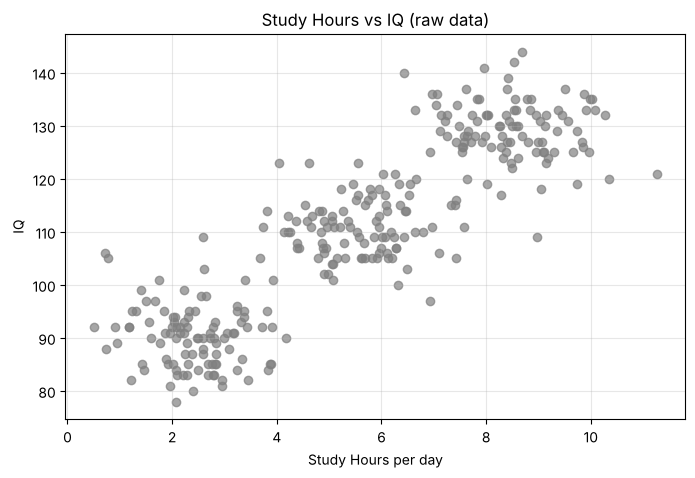

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Study_Hours"], df["IQ"], color="gray", alpha=0.7)
plt.title("Study Hours vs IQ (raw data)")
plt.xlabel("Study Hours per day")
plt.ylabel("IQ")
plt.grid(alpha=0.3)
plt.show()

## 4. Scale the features
K-Means uses distances, so both features should be on the same scale.

In [ ]:
X = df[["Study_Hours", "IQ"]].values
X_scaled = StandardScaler().fit_transform(X)

## 5. Elbow Method (WCSS)
**WCSS** = Within-Cluster Sum of Squares (called `inertia_` in scikit-learn). It measures how tightly points sit around their cluster centre. We run K-Means for K = 1 to 10 and look for the *elbow*, the point where WCSS stops dropping sharply.

In [ ]:
wcss = []
k_range = range(1, 11)

for k in k_range:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

for k, w in zip(k_range, wcss):
    print(f"K = {k:2d}  ->  WCSS = {w:.2f}")

K =  1  ->  WCSS = 600.00
K =  2  ->  WCSS = 180.79
K =  3  ->  WCSS = 66.76
K =  4  ->  WCSS = 57.46
K =  5  ->  WCSS = 49.08
K =  6  ->  WCSS = 41.12
K =  7  ->  WCSS = 35.79
K =  8  ->  WCSS = 32.00
K =  9  ->  WCSS = 27.70
K = 10  ->  WCSS = 25.34


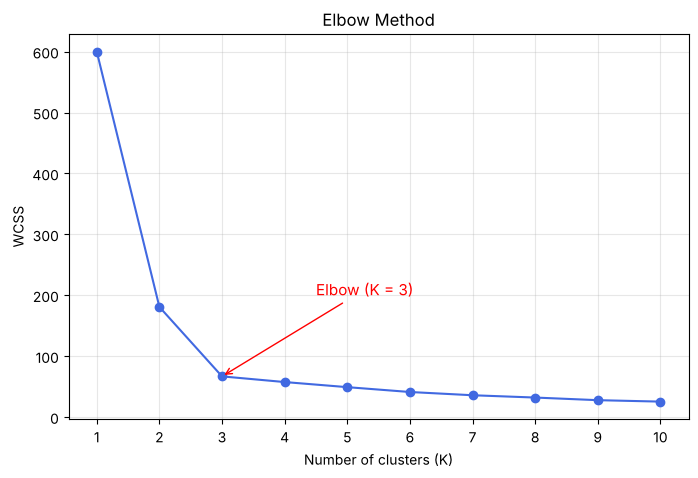

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(k_range, wcss, marker="o", color="royalblue")
plt.title("Elbow Method")
plt.xlabel("Number of clusters (K)")
plt.ylabel("WCSS")
plt.xticks(k_range)
plt.grid(alpha=0.3)
plt.annotate("Elbow (K = 3)", xy=(3, wcss[2]), xytext=(4.5, wcss[2] + (wcss[0] - wcss[2]) * 0.25),
             arrowprops=dict(arrowstyle="->", color="red"), color="red", fontsize=11)
plt.show()

The curve bends sharply at **K = 3**, so 3 is the best number of clusters.

## 6. Fit K-Means with K = 3

In [ ]:
kmeans = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=42)
df["Cluster"] = kmeans.fit_predict(X_scaled)

# Convert centroids back to the original scale for plotting
scaler = StandardScaler().fit(X)
centroids = scaler.inverse_transform(kmeans.cluster_centers_)
df.head()

,Study_Hours,IQ,Cluster
0,2.95,82,2
1,2.38,87,2
2,3.08,88,2
3,3.87,85,2
4,2.29,89,2


## 7. Visualise the clusters

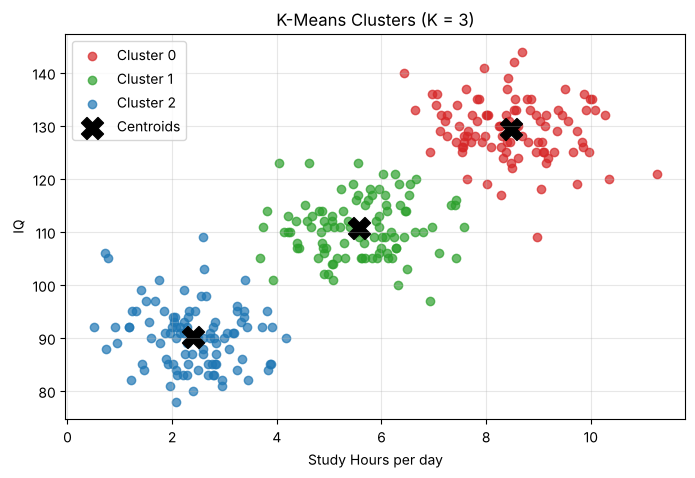

In [ ]:
colors = ["tab:red", "tab:green", "tab:blue"]

plt.figure(figsize=(8, 5))
for c in range(3):
    pts = df[df["Cluster"] == c]
    plt.scatter(pts["Study_Hours"], pts["IQ"], color=colors[c], alpha=0.7, label=f"Cluster {c}")

plt.scatter(centroids[:, 0], centroids[:, 1], color="black", marker="X", s=250, label="Centroids")
plt.title("K-Means Clusters (K = 3)")
plt.xlabel("Study Hours per day")
plt.ylabel("IQ")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 8. Cluster summary

In [ ]:
summary = df.groupby("Cluster").agg(
    Students=("IQ", "count"),
    Avg_Study_Hours=("Study_Hours", "mean"),
    Avg_IQ=("IQ", "mean")
).round(2)
summary

,Students,Avg_Study_Hours,Avg_IQ
Cluster,,,
0,99,8.48,129.35
1,101,5.57,110.71
2,100,2.40,90.26
